In [1]:
from google.colab import drive

In [2]:
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
# 1. Load all four datasets
gen1 = pd.read_csv("drive/MyDrive/Colab_Notebooks/A_DREAM_JOB/3_visualization_and_experimentation/DataSets/Plant_1_Generation_Data.csv")
gen2 = pd.read_csv("drive/MyDrive/Colab_Notebooks/A_DREAM_JOB/3_visualization_and_experimentation/DataSets/Plant_2_Generation_Data.csv")

weather1 = pd.read_csv("drive/MyDrive/Colab_Notebooks/A_DREAM_JOB/3_visualization_and_experimentation/DataSets/Plant_1_Weather_Sensor_Data.csv")
weather2 = pd.read_csv("drive/MyDrive/Colab_Notebooks/A_DREAM_JOB/3_visualization_and_experimentation/DataSets/Plant_2_Weather_Sensor_Data.csv")

# 2. Convert timestamps to datetime
# Plant 1 generation uses day-month-year formatting
gen1["DATE_TIME"] = pd.to_datetime(
    gen1["DATE_TIME"], format="%d-%m-%Y %H:%M"
)

# Other files use year-month-day formatting
gen2["DATE_TIME"] = pd.to_datetime(
    gen2["DATE_TIME"], format="%Y-%m-%d %H:%M:%S"
)

for df in [weather1, weather2]:
    df["DATE_TIME"] = pd.to_datetime(
        df["DATE_TIME"], format="%Y-%m-%d %H:%M:%S"
    )

# 3. Inspect shape, missing values, and time coverage
for name, df in {
    "Generation 1": gen1,
    "Generation 2": gen2,
    "Weather 1": weather1,
    "Weather 2": weather2
}.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Missing values:", df.isna().sum().sum())
    print("Start:", df["DATE_TIME"].min())
    print("End:", df["DATE_TIME"].max())


Generation 1
Shape: (68778, 7)
Missing values: 0
Start: 2020-05-15 00:00:00
End: 2020-06-17 23:45:00

Generation 2
Shape: (67698, 7)
Missing values: 0
Start: 2020-05-15 00:00:00
End: 2020-06-17 23:45:00

Weather 1
Shape: (3182, 6)
Missing values: 0
Start: 2020-05-15 00:00:00
End: 2020-06-17 23:45:00

Weather 2
Shape: (3259, 6)
Missing values: 0
Start: 2020-05-15 00:00:00
End: 2020-06-17 23:45:00


In [7]:
# Inspect the first five generation records
display(gen1.head())

,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,2020-05-15,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,2020-05-15,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,2020-05-15,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,2020-05-15,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


In [8]:
# Understand numerical distributions
display(gen1.describe())

,DATE_TIME,PLANT_ID,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
count,68778,68778.0,68778.000000,68778.000000,68778.000000,6.877800e+04
mean,2020-06-01 08:02:49.458256896,4135001.0,3147.426211,307.802752,3295.968737,6.978712e+06
min,2020-05-15 00:00:00,4135001.0,0.000000,0.000000,0.000000,6.183645e+06
25%,2020-05-24 00:45:00,4135001.0,0.000000,0.000000,0.000000,6.512003e+06
50%,2020-06-01 14:30:00,4135001.0,429.000000,41.493750,2658.714286,7.146685e+06
75%,2020-06-09 20:00:00,4135001.0,6366.964286,623.618750,6274.000000,7.268706e+06
max,2020-06-17 23:45:00,4135001.0,14471.125000,1410.950000,9163.000000,7.846821e+06
std,NaN,0.0,4036.457169,394.396439,3145.178309,4.162720e+05


In [9]:
# Check number of inverters
print("Plant 1 inverters:", gen1["SOURCE_KEY"].nunique())
print("Plant 2 inverters:", gen2["SOURCE_KEY"].nunique())

Plant 1 inverters: 22
Plant 2 inverters: 22


In [10]:
# Check duplicate records
print("Plant 1 duplicates:", gen1.duplicated().sum())
print("Plant 2 duplicates:", gen2.duplicated().sum())

Plant 1 duplicates: 0
Plant 2 duplicates: 0


In [11]:
# Check available timestamps
print("Plant 1 timestamps:", gen1["DATE_TIME"].nunique())
print("Plant 2 timestamps:", gen2["DATE_TIME"].nunique())

Plant 1 timestamps: 3158
Plant 2 timestamps: 3259


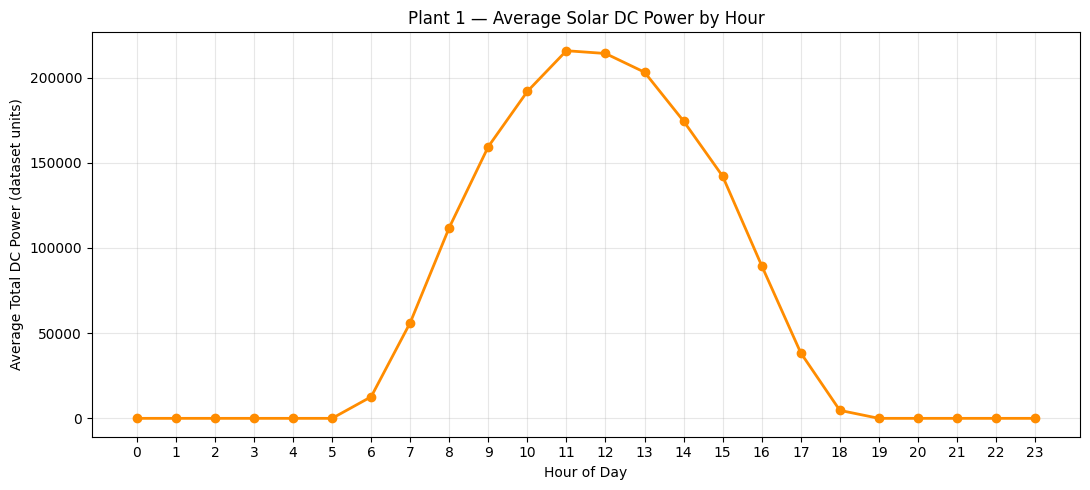

Peak Hour: 11
Average DC Power: 215722.45


In [12]:
#At what time of day does Plant 1 generate the most solar power?
# STEP 1: Extract hour from timestamp
gen1["Hour"] = gen1["DATE_TIME"].dt.hour

# STEP 2: Aggregate inverter power at each timestamp
# Important: Do not average individual inverter rows directly.
plant_power = (
    gen1.groupby("DATE_TIME", as_index=False)
    .agg(Total_DC_Power=("DC_POWER", "sum"))
)

# STEP 3: Extract hour from aggregated timestamps
plant_power["Hour"] = plant_power["DATE_TIME"].dt.hour

# STEP 4: Calculate average plant power by hour
hourly_power = (
    plant_power.groupby("Hour", as_index=False)
    .agg(Avg_DC_Power=("Total_DC_Power", "mean"))
)

# STEP 5: Plot using Matplotlib
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    hourly_power["Hour"],
    hourly_power["Avg_DC_Power"],
    marker="o",
    linewidth=2,
    color="darkorange"
)

ax.set_title("Plant 1 — Average Solar DC Power by Hour")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Average Total DC Power (dataset units)")

ax.set_xticks(range(0, 24))
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# STEP 6: Identify peak generation hour
peak = hourly_power.loc[
    hourly_power["Avg_DC_Power"].idxmax()
]

print("Peak Hour:", int(peak["Hour"]))
print("Average DC Power:", round(peak["Avg_DC_Power"], 2))

In [13]:
#Does higher solar irradiation result in higher power generation?
# Calculate total plant power at each timestamp
plant1_power = (
    gen1.groupby("DATE_TIME", as_index=False)
    .agg(DC_POWER=("DC_POWER", "sum"))
)

display(plant1_power.head())

,DATE_TIME,DC_POWER
0,2020-05-15 00:00:00,0.0
1,2020-05-15 00:15:00,0.0
2,2020-05-15 00:30:00,0.0
3,2020-05-15 00:45:00,0.0
4,2020-05-15 01:00:00,0.0


In [14]:
# Join plant power with weather readings
solar_df = pd.merge(
    plant1_power,
    weather1[["DATE_TIME", "IRRADIATION", "AMBIENT_TEMPERATURE",
              "MODULE_TEMPERATURE"]],
    on="DATE_TIME",
    how="inner",
    validate="one_to_one"
)

print("Merged shape:", solar_df.shape)

display(solar_df.head())

Merged shape: (3157, 5)


,DATE_TIME,DC_POWER,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE
0,2020-05-15 00:00:00,0.0,0.0,25.184316,22.857507
1,2020-05-15 00:15:00,0.0,0.0,25.084589,22.761668
2,2020-05-15 00:30:00,0.0,0.0,24.935753,22.592306
3,2020-05-15 00:45:00,0.0,0.0,24.846130,22.360852
4,2020-05-15 01:00:00,0.0,0.0,24.621525,22.165423


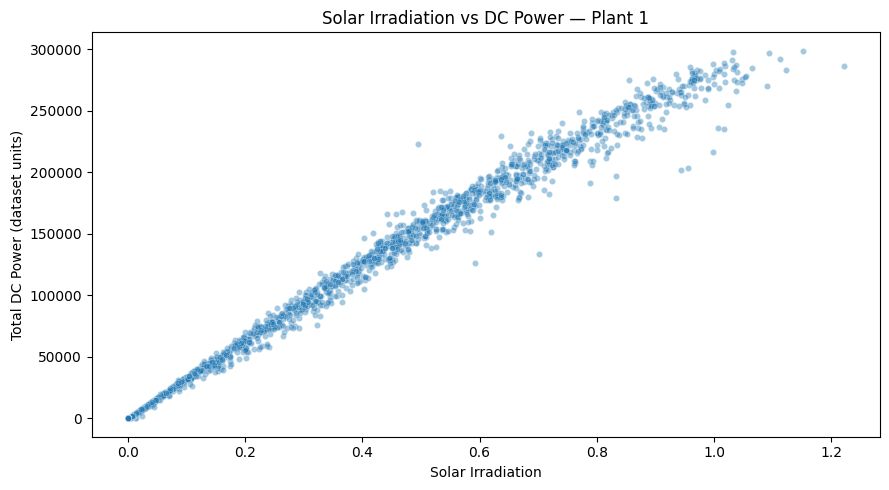

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.scatterplot(
    data=solar_df,
    x="IRRADIATION",
    y="DC_POWER",
    alpha=0.4,
    s=20,
    ax=ax
)

ax.set_title("Solar Irradiation vs DC Power — Plant 1")
ax.set_xlabel("Solar Irradiation")
ax.set_ylabel("Total DC Power (dataset units)")

plt.tight_layout()
plt.show()

In [16]:
# Pearson correlation measures linear association
correlation = solar_df["IRRADIATION"].corr(
    solar_df["DC_POWER"]
)

print(f"Correlation: {correlation:.3f}")

Correlation: 0.996


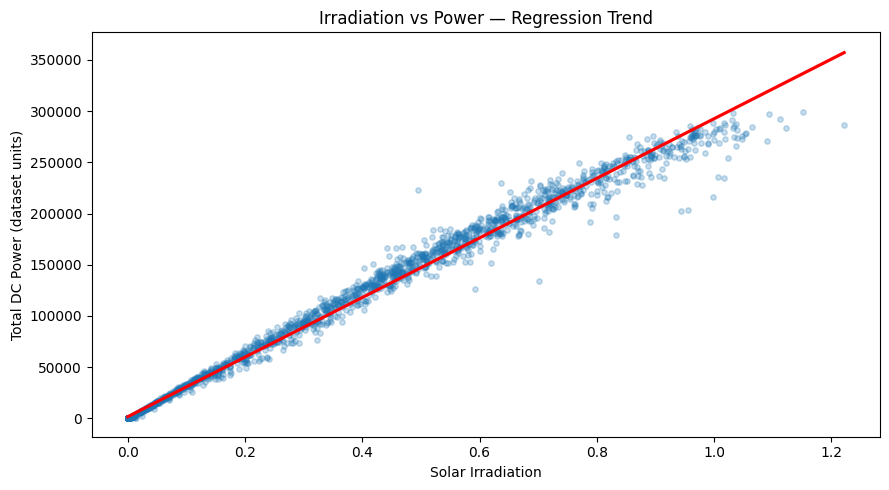

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.regplot(
    data=solar_df,
    x="IRRADIATION",
    y="DC_POWER",
    scatter_kws={"alpha": 0.25, "s": 15},
    line_kws={"color": "red"},
    ax=ax
)

ax.set_title("Irradiation vs Power — Regression Trend")
ax.set_xlabel("Solar Irradiation")
ax.set_ylabel("Total DC Power (dataset units)")

plt.tight_layout()
plt.show()

In [18]:
print("SOLAR IRRADIATION ANALYSIS")
print("-" * 35)

print(f"Correlation: {correlation:.3f}")

if correlation >= 0.7:
    print("Strong positive linear relationship.")
elif correlation >= 0.3:
    print("Moderate positive linear relationship.")
elif correlation > -0.3:
    print("Weak linear relationship.")
else:
    print("Negative linear relationship.")

print("\nBusiness Insight:")
print(
    "Investigate timestamps with high irradiation "
    "but unexpectedly low power generation."
)

SOLAR IRRADIATION ANALYSIS
-----------------------------------
Correlation: 0.996
Strong positive linear relationship.

Business Insight:
Investigate timestamps with high irradiation but unexpectedly low power generation.


In [19]:
# Restrict analysis to meaningful daylight conditions
daylight = solar_df.loc[
    (solar_df["IRRADIATION"] > 0.1) &
    (solar_df["DC_POWER"] > 0)
].copy()

# Correlation between module temperature and power
temp_corr = daylight["MODULE_TEMPERATURE"].corr(
    daylight["DC_POWER"]
)

print(f"Temperature vs Power Correlation: {temp_corr:.3f}")

Temperature vs Power Correlation: 0.889


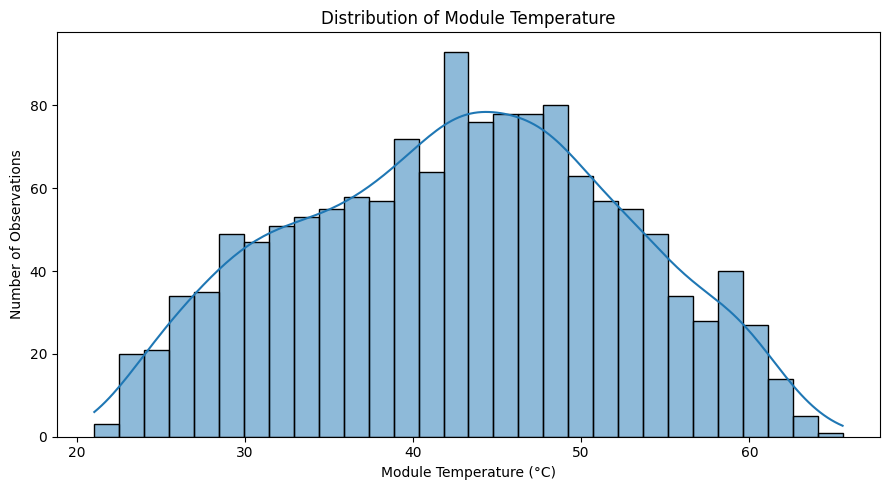

In [20]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=daylight,
    x="MODULE_TEMPERATURE",
    bins=30,
    kde=True,
    ax=ax
)

ax.set_title("Distribution of Module Temperature")
ax.set_xlabel("Module Temperature (°C)")
ax.set_ylabel("Number of Observations")

plt.tight_layout()
plt.show()

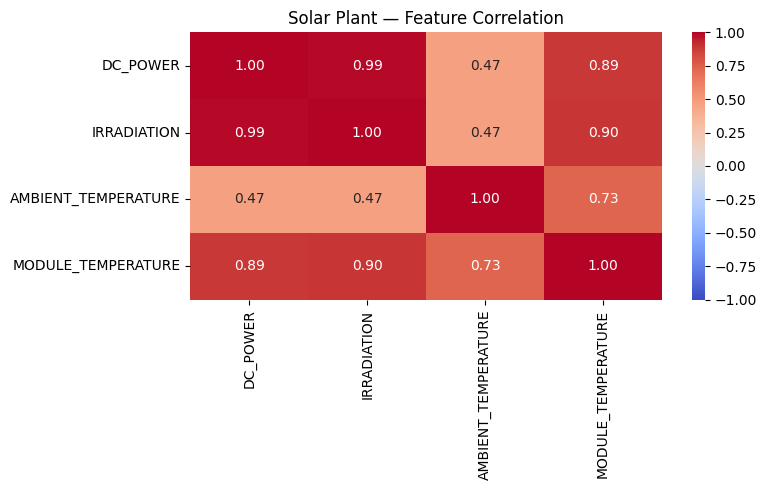

In [21]:
# Select numerical variables relevant to performance
features = [
    "DC_POWER",
    "IRRADIATION",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE"
]

corr_matrix = daylight[features].corr()

fig, ax = plt.subplots(figsize=(8, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=ax
)

ax.set_title("Solar Plant — Feature Correlation")

plt.tight_layout()
plt.show()

In [22]:
#Which solar plant delivers more consistent power generation?
# Extract calendar dates
gen1["Date"] = gen1["DATE_TIME"].dt.date
gen2["Date"] = gen2["DATE_TIME"].dt.date

# Find maximum daily yield for each inverter
daily1 = (
    gen1.groupby(["Date", "SOURCE_KEY"])["DAILY_YIELD"]
    .max()
    .groupby("Date")
    .sum()
    .reset_index(name="Daily_Yield")
)

daily2 = (
    gen2.groupby(["Date", "SOURCE_KEY"])["DAILY_YIELD"]
    .max()
    .groupby("Date")
    .sum()
    .reset_index(name="Daily_Yield")
)

# Identify plants
daily1["Plant"] = "Plant 1"
daily2["Plant"] = "Plant 2"

# Combine datasets
daily = pd.concat([daily1, daily2], ignore_index=True)

display(daily.head())

,Date,Daily_Yield,Plant
0,2020-05-15,137473.000,Plant 1
1,2020-05-16,142114.000,Plant 1
2,2020-05-17,165106.000,Plant 1
3,2020-05-18,117738.000,Plant 1
4,2020-05-19,149637.125,Plant 1


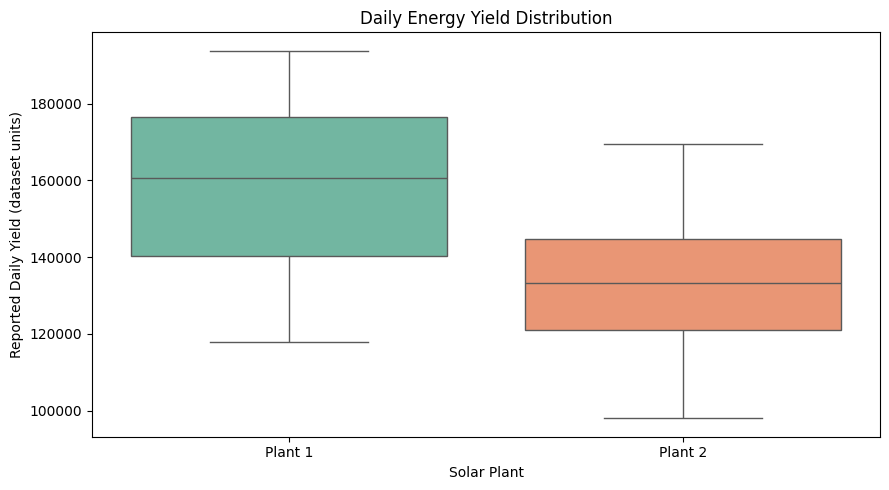

In [23]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=daily,
    x="Plant",
    y="Daily_Yield",
    hue="Plant",
    palette="Set2",
    legend=False,
    ax=ax
)

ax.set_title("Daily Energy Yield Distribution")
ax.set_xlabel("Solar Plant")
ax.set_ylabel("Reported Daily Yield (dataset units)")

plt.tight_layout()
plt.show()

In [24]:
plant_metrics = (
    daily.groupby("Plant")["Daily_Yield"]
    .agg(["mean", "median", "std", "min", "max"])
)

# Coefficient of variation = Std / Mean × 100
plant_metrics["CV_Percent"] = (
    plant_metrics["std"] / plant_metrics["mean"] * 100
)

display(plant_metrics.round(2))

,mean,median,std,min,max,CV_Percent
Plant,,,,,,
Plant 1,158258.79,160510.92,21929.50,117738.0,193770.0,13.86
Plant 2,131751.93,133162.90,17444.26,97966.0,169356.0,13.24


In [25]:
# Align plants by calendar date
paired = daily1[["Date", "Daily_Yield"]].merge(
    daily2[["Date", "Daily_Yield"]],
    on="Date",
    suffixes=("_P1", "_P2"),
    validate="one_to_one"
)

# Daily difference
paired["Difference"] = (
    paired["Daily_Yield_P2"] -
    paired["Daily_Yield_P1"]
)

print("Matched days:", len(paired))
display(paired.head())

Matched days: 34


,Date,Daily_Yield_P1,Daily_Yield_P2,Difference
0,2020-05-15,137473.000,169356.000000,31883.000000
1,2020-05-16,142114.000,147356.933333,5242.933333
2,2020-05-17,165106.000,139414.000000,-25692.000000
3,2020-05-18,117738.000,132159.000000,14421.000000
4,2020-05-19,149637.125,116953.000000,-32684.125000


In [26]:
from scipy.stats import ttest_rel

# Compare yields on matching dates
t_stat, p_value = ttest_rel(
    paired["Daily_Yield_P1"],
    paired["Daily_Yield_P2"]
)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

alpha = 0.05

if p_value < alpha:
    print("Statistically significant difference.")
else:
    print("Insufficient evidence of a difference.")

T-statistic: 6.9660
P-value: 0.0000
Statistically significant difference.


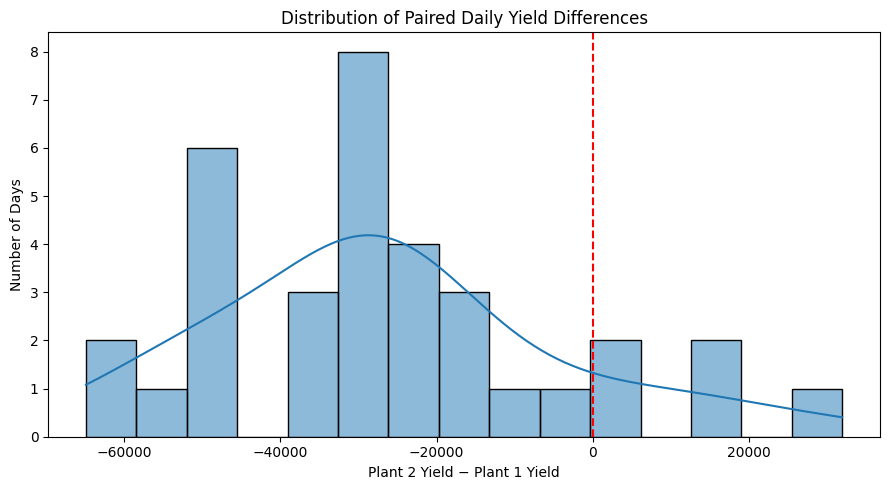

In [27]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=paired,
    x="Difference",
    bins=15,
    kde=True,
    ax=ax
)

# Zero means equal daily yield
ax.axvline(0, color="red", linestyle="--")

ax.set_title("Distribution of Paired Daily Yield Differences")
ax.set_xlabel("Plant 2 Yield − Plant 1 Yield")
ax.set_ylabel("Number of Days")

plt.tight_layout()
plt.show()

In [28]:
# Daily energy yield statistics
kpis = (
    daily.groupby("Plant")
    .agg(
        Total_Reported_Yield=("Daily_Yield", "sum"),
        Average_Daily_Yield=("Daily_Yield", "mean"),
        Median_Daily_Yield=("Daily_Yield", "median"),
        Days_Recorded=("Date", "nunique")
    )
)

display(kpis.round(2))

,Total_Reported_Yield,Average_Daily_Yield,Median_Daily_Yield,Days_Recorded
Plant,,,,
Plant 1,5380798.92,158258.79,160510.92,34
Plant 2,4479565.45,131751.93,133162.90,34


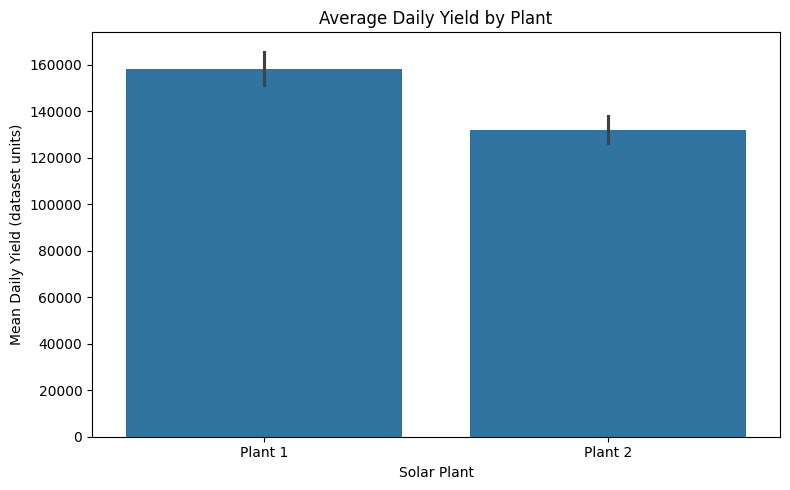

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=daily,
    x="Plant",
    y="Daily_Yield",
    estimator="mean",
    errorbar=("ci", 95),
    ax=ax
)

ax.set_title("Average Daily Yield by Plant")
ax.set_xlabel("Solar Plant")
ax.set_ylabel("Mean Daily Yield (dataset units)")

plt.tight_layout()
plt.show()

In [30]:
# Compare average daily yields
avg1 = daily1["Daily_Yield"].mean()
avg2 = daily2["Daily_Yield"].mean()

# Average paired difference
mean_diff = paired["Difference"].mean()

print("SOLAR POWER PERFORMANCE REPORT")
print("=" * 40)

print(f"Plant 1 Average Daily Yield: {avg1:,.2f}")
print(f"Plant 2 Average Daily Yield: {avg2:,.2f}")
print(f"Matched-Day Mean Difference: {mean_diff:,.2f}")

print("\nStatistical Test:")
print(f"P-value: {p_value:.4f}")

print("\nBusiness Recommendation:")

print(
    "Investigate yield variability, missing readings, "
    "inverter performance, and irradiation patterns "
    "before deciding which plant performs better."
)

SOLAR POWER PERFORMANCE REPORT
Plant 1 Average Daily Yield: 158,258.79
Plant 2 Average Daily Yield: 131,751.93
Matched-Day Mean Difference: -26,506.87

Statistical Test:
P-value: 0.0000

Business Recommendation:
Investigate yield variability, missing readings, inverter performance, and irradiation patterns before deciding which plant performs better.
